#**Carregamento de Bibliotecas**

In [ ]:
!pip install catboost
!pip install lightgbm
!pip install xgboost

  Using cached catboost-1.2.10-cp313-cp313-manylinux2014_x86_64.whl.metadata (1.4 kB)
Using cached catboost-1.2.10-cp313-cp313-manylinux2014_x86_64.whl (97.1 MB)


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib.patches import Rectangle
import seaborn as sns

from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.base import clone
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, precision_score, recall_score, f1_score

from collections import Counter
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

# **Matriz de Confusão personalizada**

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names, model_name):
    cm = confusion_matrix(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)

    # Precisão por coluna (previsto), Recall por linha (real)
    precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    recall = recall_score(y_true, y_pred, average=None, zero_division=0)

    n_classes = len(class_names)

    # Matriz estendida: última linha = recall, última coluna = precisão
    cm_ext = np.zeros((n_classes + 1, n_classes + 1), dtype=float)
    cm_ext[:n_classes, :n_classes] = cm
    cm_ext[:n_classes, n_classes] = recall * 100     # última coluna: precisão
    cm_ext[n_classes, :n_classes] = precision * 100        # última linha: recall

    # Rótulos
    x_labels = list(class_names) + ['Recall (%)']
    y_labels = list(class_names) + ['Precisão (%)']

    # Plot base
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(cm_ext, annot=False, fmt=".1f", cmap="Greys", xticklabels=x_labels, yticklabels=y_labels,
                cbar=False, ax=ax, linewidths=0.5, linecolor='gray', vmin=0)

    # Cores personalizadas
    for i in range(n_classes + 1):
        for j in range(n_classes + 1):
            if i < n_classes and j < n_classes:
                color = '#c2f0c2' if i == j else '#f7c2c2'  # Verde claro se acerto, vermelho claro se erro
            elif i == n_classes or j == n_classes:
                color = '#d0d0ff'  # Azul claro para recall/precisão
            else:
                color = 'white'

            ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))

            # Texto exibido
            val = cm_ext[i, j]
            if i < n_classes and j < n_classes:
                total = cm_ext[i, :n_classes].sum()
                pct = 100 * val / total if total > 0 else 0
                text = f"{int(val)}\n{pct:.1f}%"
            elif val > 0:
                text = f"{val:.1f}%"
            else:
                text = ""

            ax.text(j + 0.5, i + 0.5, text, ha='center', va='center', color='black', fontsize=10)

    ax.set_title(f"{model_name} — Matriz de Confusão (Acurácia = {acc*100:.2f}%)")
    ax.set_xlabel("Classe Prevista (Predicted)")
    ax.set_ylabel("Classe Real (True)")
    plt.tight_layout()
    plt.show()

# **Carregamento do Dataset**

In [ ]:
df = pd.read_csv('https://drive.google.com/uc?export=download&id=1eP7qDGoxO873s9kxvsJkY1G55NT3DXpZ')
df.head()

,session_id,capture_date,window_start_ts,window_end_ts,window_duration_s,vpn_type,client_vm,server_vm,total_packets,total_bytes,...,byte_quartile_4,early_vs_late_ratio,max_rate_quartile,std_rate_quartiles,packet_quartile_1,packet_quartile_2,packet_quartile_3,packet_quartile_4,service,category
0,captura_20251205_174048,2025-12-05 17:40:48,1.764967e+09,1.764967e+09,12.630514,OpenVPN,client_vm,server_vm,7146,10777244,...,0.000025,19665.503650,1,0.432983,0.999440,0.000000,0.000280,0.000280,Download,Download
1,captura_20251205_174036,2025-12-05 17:40:36,1.764967e+09,1.764967e+09,7.666513,OpenVPN,client_vm,server_vm,8100,12236308,...,0.796698,0.000014,4,0.326364,0.000123,0.000000,0.204938,0.794938,Download,Download
2,captura_20251205_174140,2025-12-05 17:41:40,1.764967e+09,1.764967e+09,3.147433,OpenVPN,client_vm,server_vm,10109,15286844,...,0.241716,1.000749,2,0.024152,0.217826,0.282916,0.257790,0.241468,Download,Download
3,captura_20251205_174044,2025-12-05 17:40:44,1.764967e+09,1.764967e+09,3.411016,OpenVPN,client_vm,server_vm,11004,16646789,...,0.245810,0.891249,3,0.034625,0.195747,0.275900,0.282715,0.245638,Download,Download
4,captura_20251205_174220,2025-12-05 17:42:20,1.764967e+09,1.764967e+09,3.521655,OpenVPN,client_vm,server_vm,10488,15862456,...,0.287640,0.831784,4,0.029152,0.207094,0.247521,0.258009,0.287376,Download,Download


# **Cálculo e Plot da matriz de correlação**

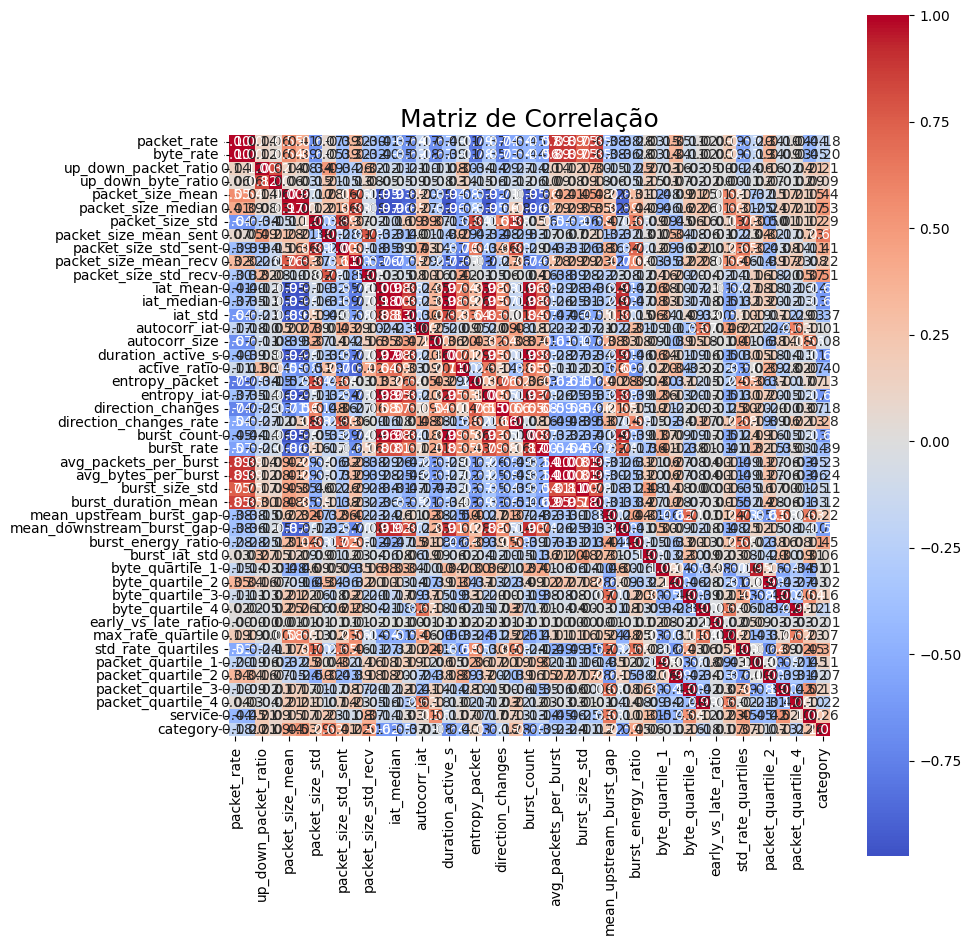


=== Correlação das features com 'category' ===

category                             ->  +1.0000
iat_median                           ->  -0.6469
duration_active_s                    ->  -0.6380
entropy_iat                          ->  -0.6364
packet_size_mean_sent                ->  +0.6318
iat_mean                             ->  -0.6179
burst_count                          ->  -0.6018
mean_downstream_burst_gap            ->  -0.5901
packet_size_median                   ->  +0.5269
packet_size_std_recv                 ->  +0.5067
burst_energy_ratio                   ->  +0.4468
packet_size_mean                     ->  +0.4363
packet_size_std_sent                 ->  +0.4059
active_ratio                         ->  -0.3987
burst_rate                           ->  -0.3915
iat_std                              ->  -0.3713
std_rate_quartiles                   ->  +0.3707
packet_size_std                      ->  +0.2891
direction_changes_rate               ->  +0.2793
service             

In [ ]:
# Copia o DataFrame para não afetar o original
df_corr = df.copy()
df_corr = df_corr.drop(['session_id', 'capture_date', 'window_start_ts', 'window_end_ts', 'window_duration_s', 'vpn_type', 'client_vm', 'server_vm', 'total_packets', 'total_bytes', 'packets_sent', 'packets_recv', 'bytes_sent', 'bytes_recv'], axis=1)
# Converte a classe para valores numéricos
le_service = LabelEncoder()
le_category = LabelEncoder()
df_corr['service'] = le_service.fit_transform(df_corr['service'])
df_corr['category'] = le_category.fit_transform(df_corr['category'])
plt.figure(figsize=(10, 10))
corr_matrix = df_corr.corr()
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, center=0)
plt.title("Matriz de Correlação", fontsize=18)
plt.tight_layout()
plt.show()

#print(corr_matrix)

category_corr = corr_matrix['category']
category_corr_sorted = category_corr.reindex(category_corr.abs().sort_values(ascending=False).index)
print("\n=== Correlação das features com 'category' ===\n")
for feature, corr in category_corr_sorted.items():
    print(f"{feature:35s}  ->  {corr:+.4f}")

# **Seleção das features úteis**

In [ ]:
target = 'category'
df = df.dropna()

# Remover features absolutas
df = df.drop(columns=['burst_count', 'direction_changes', 'total_packets', 'total_bytes', 'packets_sent', 'packets_recv', 'bytes_sent', 'bytes_recv', 'duration_active_s'], axis=1)

# Remover metadados (não são úteis para classificação)
df = df.drop(['session_id', 'capture_date', 'window_start_ts', 'window_end_ts', 'window_duration_s', 'vpn_type', 'client_vm', 'server_vm'], axis=1)

# Remover colunas alvo
X = df.drop(['service', 'category'], axis=1)
y = df[target]

# **Pré-Processamento**

In [ ]:
# Codificação da classe
le = LabelEncoder()
y_encoded = le.fit_transform(y)

unique_values, counts = np.unique(y_encoded, return_counts=True)
print("Unique values:", unique_values)
print("Counts:", counts)
nan_count_per_column = df.isna().sum()
print(nan_count_per_column)
total_nan_count = df.isna().sum().sum()
print(f"Total NaN count in DataFrame: {total_nan_count}")

Unique values: [0 1 2 3 4 5]
Counts: [1023 1000 1002 1067 1011 1011]
packet_rate                  0
byte_rate                    0
up_down_packet_ratio         0
up_down_byte_ratio           0
packet_size_mean             0
packet_size_median           0
packet_size_std              0
packet_size_mean_sent        0
packet_size_std_sent         0
packet_size_mean_recv        0
packet_size_std_recv         0
iat_mean                     0
iat_median                   0
iat_std                      0
autocorr_iat                 0
autocorr_size                0
active_ratio                 0
entropy_packet               0
entropy_iat                  0
direction_changes_rate       0
burst_rate                   0
avg_packets_per_burst        0
avg_bytes_per_burst          0
burst_size_std               0
burst_duration_mean          0
mean_upstream_burst_gap      0
mean_downstream_burst_gap    0
burst_energy_ratio           0
burst_iat_std                0
byte_quartile_1              0
b

# **Análise de Balanceamento**

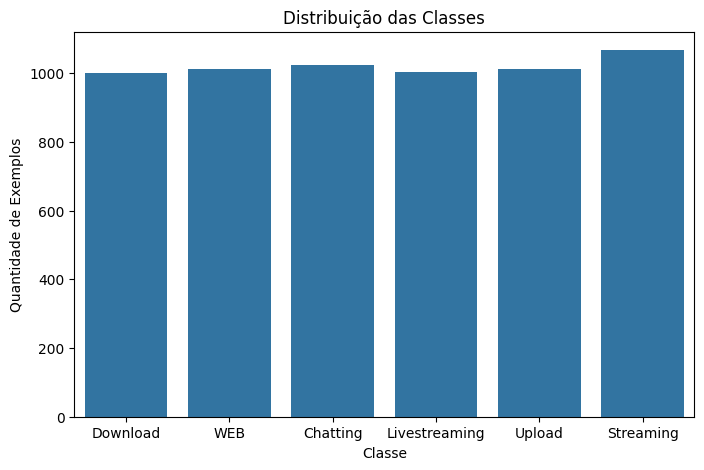

In [ ]:
plt.figure(figsize=(8, 5))
sns.countplot(x='category', data=df)
plt.title("Distribuição das Classes")
plt.xlabel("Classe")
plt.ylabel("Quantidade de Exemplos")
plt.show()

# **Definição dos Modelos**

In [ ]:
#TODO adaptar
model_configs = {
    "CatBoost": {
        "model": CatBoostClassifier(
            verbose=0,
            random_state=42,
            task_type="CPU"
        ),
        "params": {
            "clf__depth": [4, 6, 8],
            "clf__learning_rate": [0.03, 0.1],
            "clf__iterations": [200, 500],
            "clf__l2_leaf_reg": [1, 3, 5]
        },
    },

    "LightGBM": {
        "model": LGBMClassifier(random_state=42),
        "params": {
            "clf__num_leaves": [31, 63],
            "clf__learning_rate": [0.03, 0.1],
            "clf__n_estimators": [200, 500],
            "clf__max_depth": [-1, 5, 10]
        },
    },

    "RandomForest": {
        "model": RandomForestClassifier(random_state=42),
        "params": {
            "clf__n_estimators": [100, 200],
            "clf__max_depth": [10, 20, None],
            "clf__max_features": ["sqrt", "log2"]
        }
    },

    "SVM": {
        "model": SVC(probability=True, random_state=42),
        "params": {
            "clf__C": [0.1, 1, 10],
            "clf__gamma": ["scale", "auto"]
        }
    },

    "MLP": {
        "model": MLPClassifier(random_state=42, max_iter=500),
        "params": {
            "clf__hidden_layer_sizes": [(50,),(100,),(50,50),(100,50),(128,64)],
            "clf__activation": ["relu", "tanh"],
            "clf__alpha": [0.0001, 0.001]
        }
    }
}

# **GridSearch com validação cruzada para otimização de hiperparâmetros**

In [ ]:
# 2. Aplicação do GridSearch com pipeline para cada modelo
best_params = {}
best_scores = {}
test_scores = {}

total_nan_count = df.isna().sum().sum()
print(f"Total NaN count in DataFrame: {total_nan_count}")

X_train, X_test, y_train, y_test = train_test_split(X, y_encoded, test_size=0.3, stratify=y, random_state=42)

for name, config in model_configs.items():
    print(f"\n🔍 Treinando modelo: {name}")

    pipeline = ImbPipeline([
        #("smote", SMOTE(random_state=42)),
        ("scaler", StandardScaler()),
        ("clf", config["model"])
    ])

    # Busca a configuração de paralelismo do modelo, padrão é -1
    model_n_jobs = config.get("n_jobs", -1)

    grid = GridSearchCV(
        pipeline,
        param_grid=config["params"],
        scoring="f1_macro",
        cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
        n_jobs=model_n_jobs,
        verbose=1
    )

    grid.fit(X_train, y_train)
    test_score = grid.score(X_test, y_test)

    best_params[name] = grid.best_params_
    best_scores[name] = grid.best_score_
    test_scores[name] = test_score

    print(f"✅ Melhor f1-macro para {name}: {grid.best_score_:.4f}")
    print(f"🎯 F1-macro no TESTE: {test_score:.4f}")
    print(f"📌 Melhores hiperparâmetros: {grid.best_params_}")

    if grid.best_score_ > test_score + 0.05:
        print(f"Atenção: possível overfitting em {name}")


Total NaN count in DataFrame: 0

🔍 Treinando modelo: CatBoost
Fitting 5 folds for each of 36 candidates, totalling 180 fits
✅ Melhor f1-macro para CatBoost: 0.9998
🎯 F1-macro no TESTE: 0.9994
📌 Melhores hiperparâmetros: {'clf__depth': 4, 'clf__iterations': 200, 'clf__l2_leaf_reg': 5, 'clf__learning_rate': 0.1}

🔍 Treinando modelo: LightGBM
Fitting 5 folds for each of 24 candidates, totalling 120 fits
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002111 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9752
[LightGBM] [Info] Number of data points in the train set: 4279, number of used features: 40
[LightGBM] [Info] Start training from score -1.787794
[LightGBM] [Info] Start training from score -1.810394
[LightGBM] [Info] Start training from score -1.808967
[LightGBM] [Info] Start training from score -1.745409
[LightGBM] [Info] Start training from score -1.800444
[LightGBM] [Info] Start training from 

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


✅ Melhor f1-macro para LightGBM: 0.9993
🎯 F1-macro no TESTE: 0.9984
📌 Melhores hiperparâmetros: {'clf__learning_rate': 0.1, 'clf__max_depth': 5, 'clf__n_estimators': 200, 'clf__num_leaves': 31}

🔍 Treinando modelo: RandomForest
Fitting 5 folds for each of 12 candidates, totalling 60 fits
✅ Melhor f1-macro para RandomForest: 0.9998
🎯 F1-macro no TESTE: 0.9994
📌 Melhores hiperparâmetros: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__n_estimators': 100}

🔍 Treinando modelo: SVM
Fitting 5 folds for each of 6 candidates, totalling 30 fits
✅ Melhor f1-macro para SVM: 0.9979
🎯 F1-macro no TESTE: 0.9967
📌 Melhores hiperparâmetros: {'clf__C': 10, 'clf__gamma': 'scale'}

🔍 Treinando modelo: MLP
Fitting 5 folds for each of 20 candidates, totalling 100 fits
✅ Melhor f1-macro para MLP: 0.9991
🎯 F1-macro no TESTE: 0.9978
📌 Melhores hiperparâmetros: {'clf__activation': 'relu', 'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (100, 50)}


# **Treinamento e avaliação dos modelos com os melhores parâmetros**


===== Treinando modelo final: CatBoost =====
Acurácia: 0.9995


/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


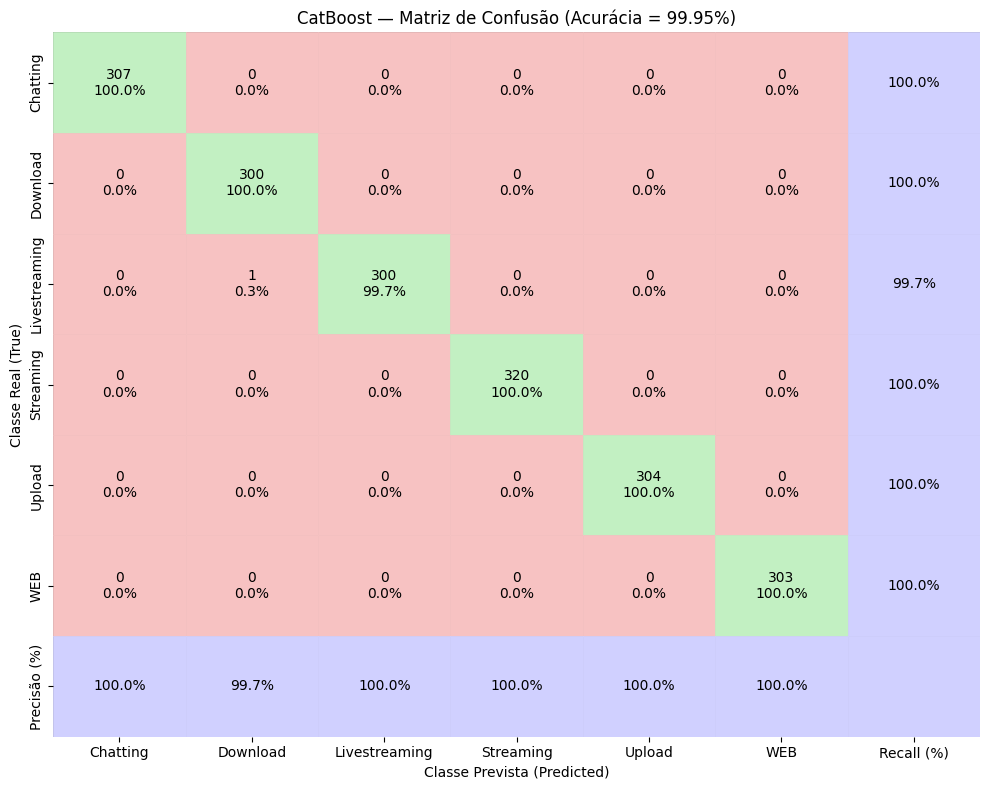

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      1.00      1.00       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       1.00      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


===== Treinando modelo final: LightGBM =====
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002314 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9752
[LightGBM] [Info] Number of data points in the train set: 4279, number of used features: 40
[LightGBM] [Info] Start training from score -1.787794
[LightGBM] [Info] Start traini

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


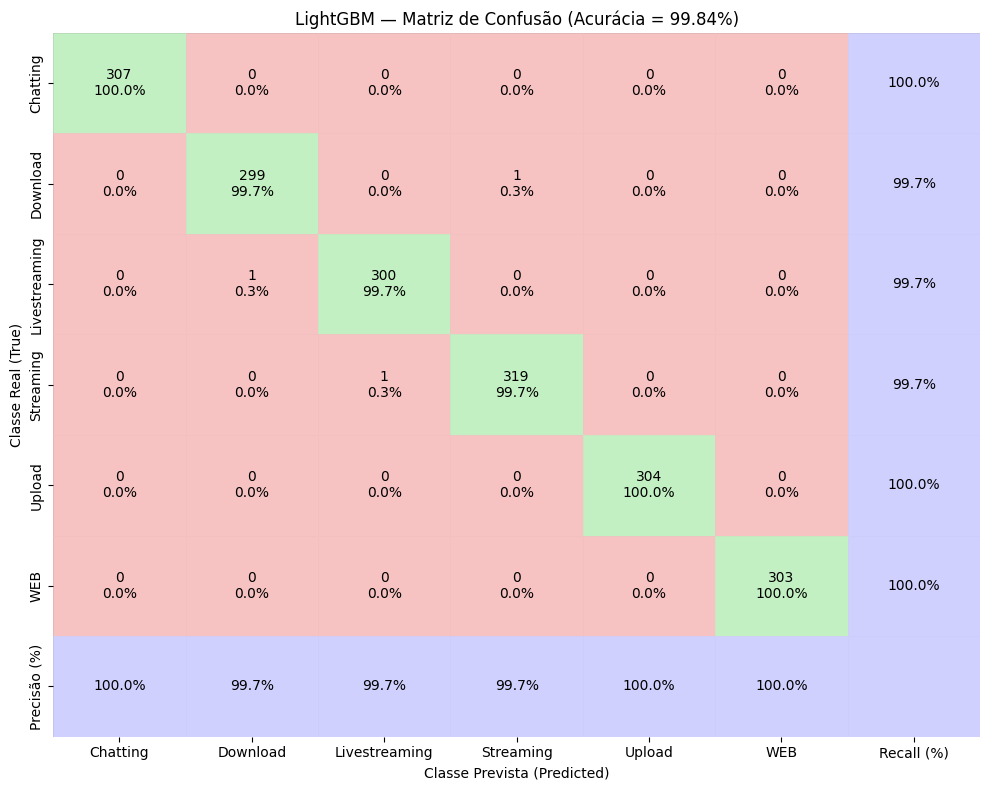

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      1.00      1.00       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       1.00      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


===== Treinando modelo final: RandomForest =====
Acurácia: 0.9995


/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


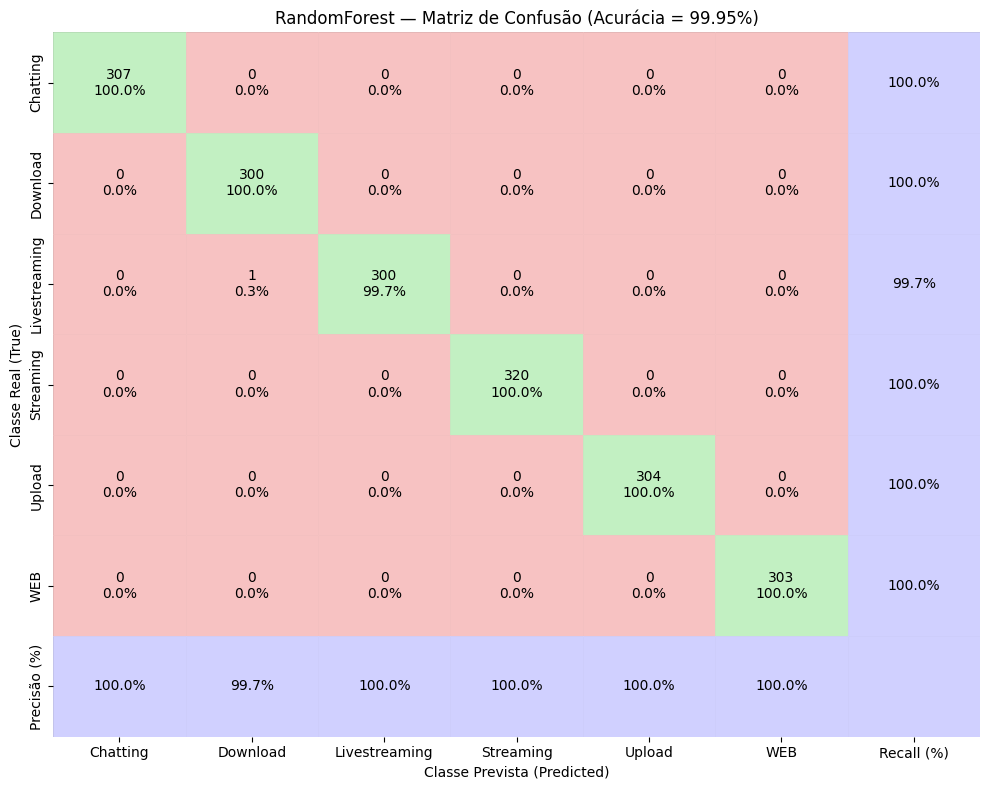

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      1.00      1.00       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       1.00      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


===== Treinando modelo final: SVM =====
Acurácia: 0.9967


/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


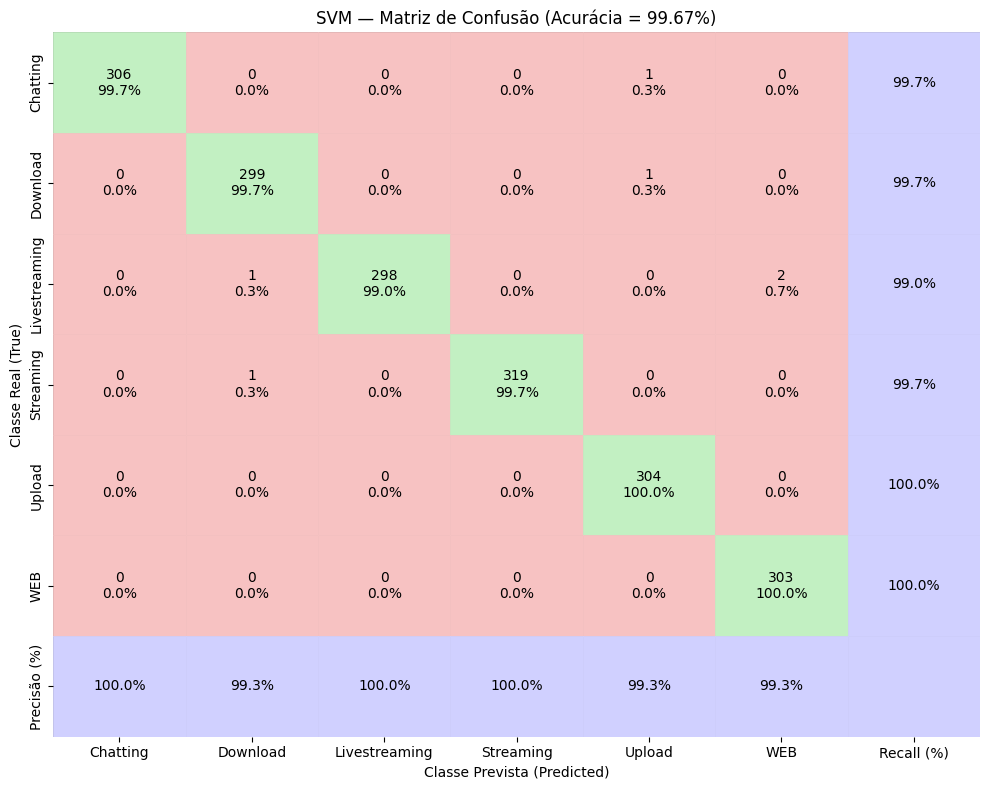

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       0.99      1.00      1.00       300
Livestreaming       1.00      0.99      0.99       301
    Streaming       1.00      1.00      1.00       320
       Upload       0.99      1.00      1.00       304
          WEB       0.99      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


===== Treinando modelo final: MLP =====
Acurácia: 0.9978


/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


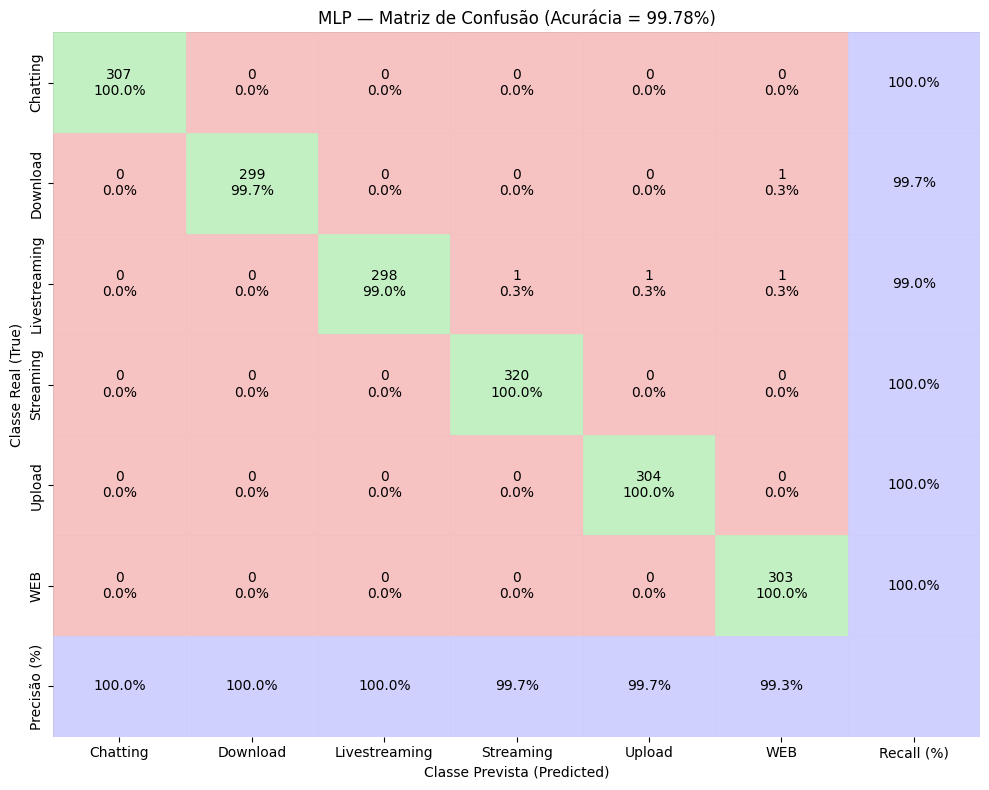

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      0.99      0.99       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       0.99      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


==== Resultados finais ====
CatBoost -> Acurácia: 0.9995 | F1-Macro: 0.9994
LightGBM -> Acurácia: 0.9984 | F1-Macro: 0.9984
RandomForest -> Acurácia: 0.9995 | F1-Macro: 0.9994
SVM -> Acurácia: 0.9967 | F1-Macro: 0.9967
MLP -> Acurácia: 0.9978 | F1-Macro: 0.9978


In [ ]:
# === Etapa 1: Dividir os dados ===

# OBS: X_train X_test, y_train e y_test estão sendo aproveitados do train_test_split feito na célula anterior

# === Função auxiliar para converter "clf__param" → "param" ===
def clean_params(params):
    return {k.split("__")[1]: v for k, v in params.items()}

# === Etapa 2: Construir pipelines finais usando os melhores hiperparâmetros ===
final_pipelines = {}

for model_name, config in model_configs.items():
    if model_name not in best_params:
        continue

    # Monta pipeline final: SMOTE → Scaler → Modelo
    final_pipeline = ImbPipeline([
        #("smote", SMOTE(random_state=42)),
        ("scaler", StandardScaler()),
        ("clf", clone(config["model"]).set_params(**clean_params(best_params[model_name])))
    ])

    final_pipelines[model_name] = final_pipeline


# === Etapa 3: Treinar e avaliar ===
results = {}

for name, pipeline in final_pipelines.items():

    print(f"\n===== Treinando modelo final: {name} =====")

    pipeline.fit(X_train, y_train)

    # Predição no conjunto de teste (dados de teste sem SMOTE nem Scaler pra evitar vazamento)
    y_pred = pipeline.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average='macro')
    cm = confusion_matrix(y_test, y_pred)
    report = classification_report(y_test, y_pred, target_names=le.classes_)

    print(f"Acurácia: {acc:.4f}")
    plot_confusion_matrix(y_test, y_pred, class_names=le.classes_, model_name=name)
    print("Relatório de Classificação:\n", report)

    results[name] = {
        'Acurácia': acc,
        'F1-Macro': f1_macro
    }

print("\n==== Resultados finais ====")
for model, metrics in results.items():
    print(f"{model} -> Acurácia: {metrics['Acurácia']:.4f} | F1-Macro: {metrics['F1-Macro']:.4f}")


# [2] Treinamento final e avaliação com Feature Importance


==================== Treinando modelo final: CatBoost ====================
Acurácia: 0.9995 | F1-Macro: 0.9994


/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


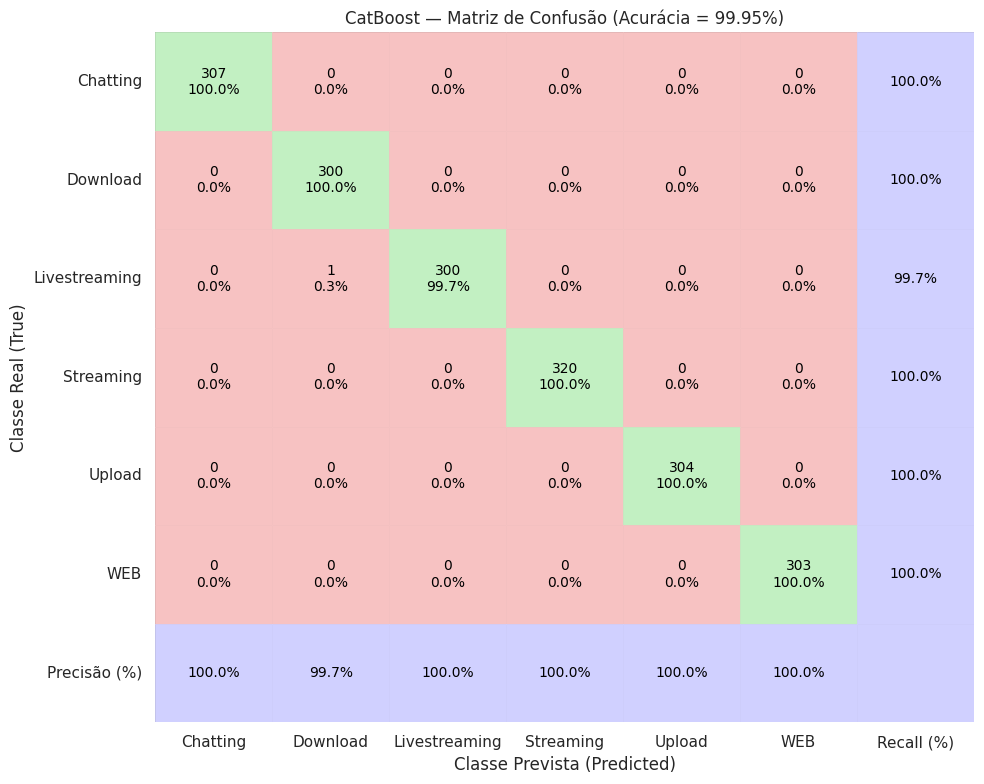

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      1.00      1.00       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       1.00      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


📊 Top 15 Feature Importances (CatBoost):
   1º | packet_size_median             | 17.049583
   2º | packet_size_mean_recv          | 14.990119
   3º | up_down_packet_ratio           | 9.195428
   4º | packet_size_std_sent           | 7.430970
   5º | burst_rate                     | 6.716178
   6º | up_down_byte_ratio             | 5.926774
   7º | packet_size_mean_sent          | 5.755570
   8º | iat_std         

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


Acurácia: 0.9984 | F1-Macro: 0.9984


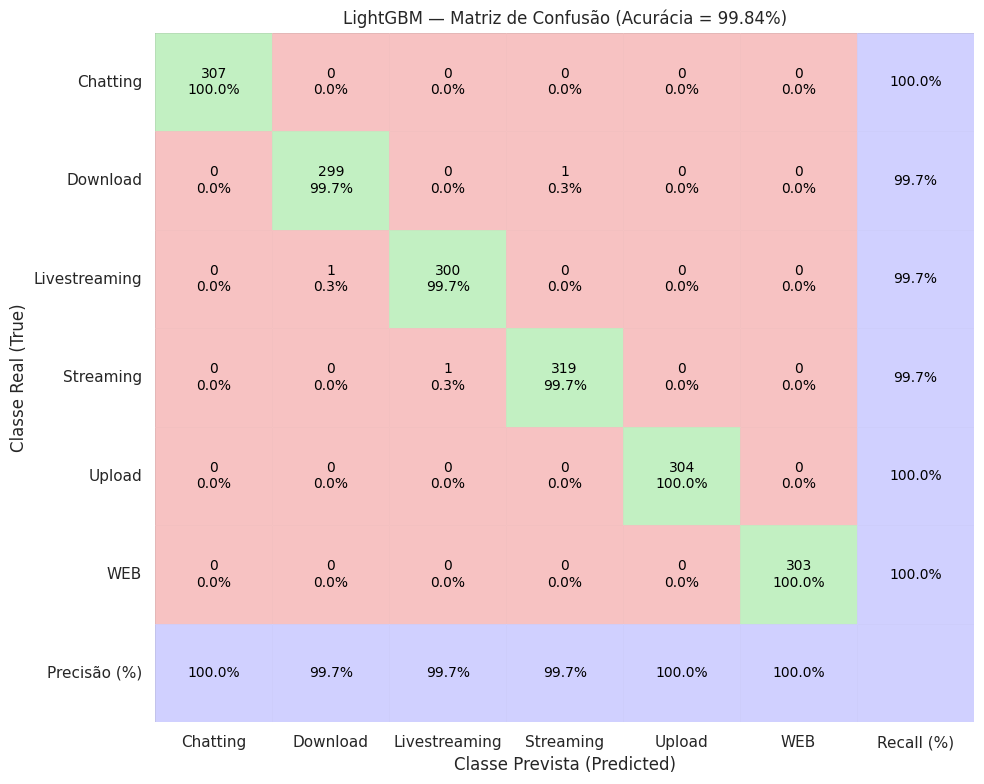

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      1.00      1.00       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       1.00      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


📊 Top 15 Feature Importances (LightGBM):
   1º | autocorr_iat                   | 751.000000
   2º | packet_size_std_sent           | 475.000000
   3º | mean_upstream_burst_gap        | 440.000000
   4º | direction_changes_rate         | 323.000000
   5º | packet_quartile_3              | 317.000000
   6º | packet_size_median             | 304.000000
   7º | packet_size_mean_sent          | 288.000000
   8º | earl

/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


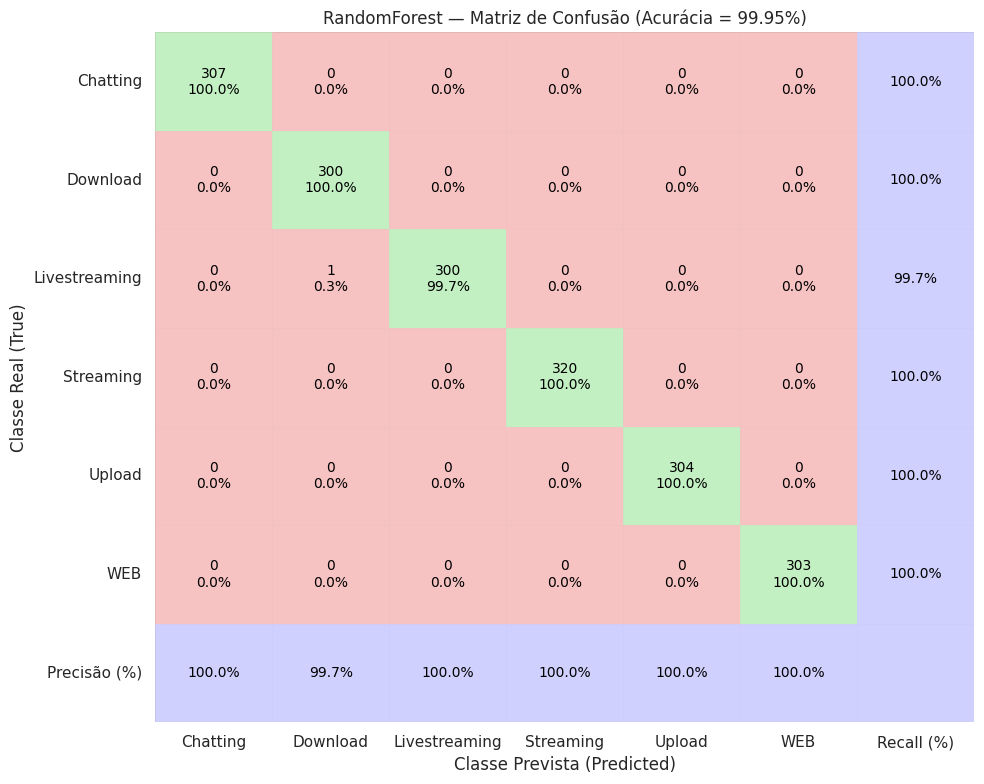

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      1.00      1.00       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       1.00      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


📊 Top 15 Feature Importances (RandomForest):
   1º | up_down_byte_ratio             | 0.096686
   2º | mean_upstream_burst_gap        | 0.092011
   3º | packet_size_median             | 0.080082
   4º | packet_size_std_sent           | 0.076225
   5º | packet_size_mean_sent          | 0.064246
   6º | mean_downstream_burst_gap      | 0.057715
   7º | packet_size_mean_recv          | 0.055586
   8º | byte_rate     

/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


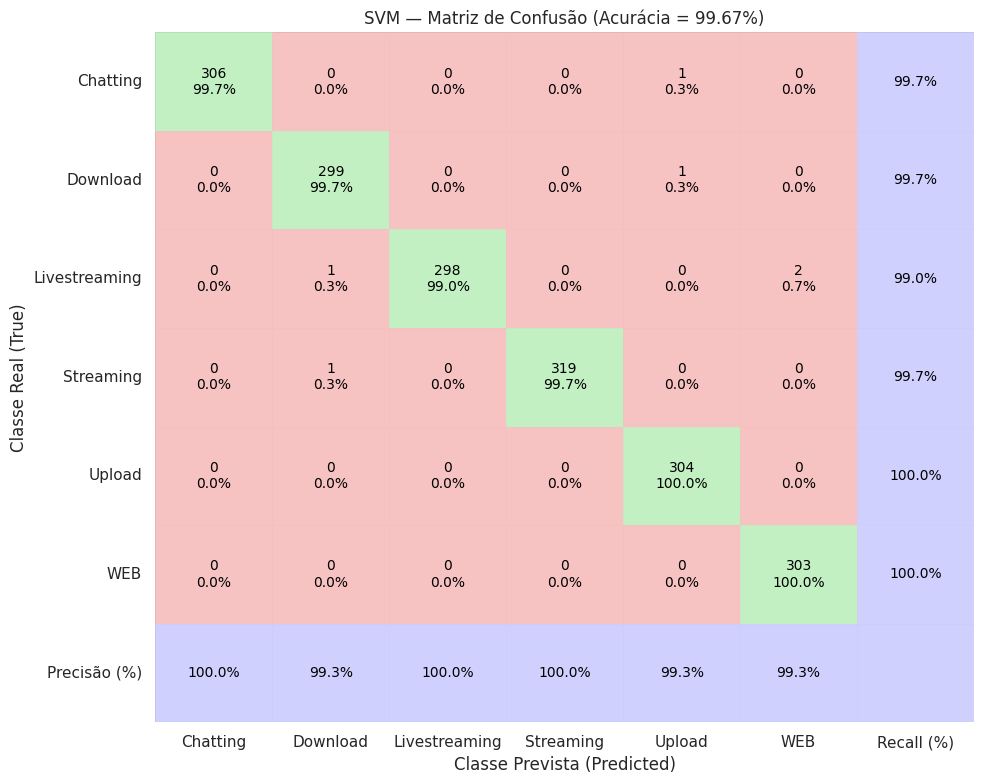

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       0.99      1.00      1.00       300
Livestreaming       1.00      0.99      0.99       301
    Streaming       1.00      1.00      1.00       320
       Upload       0.99      1.00      1.00       304
          WEB       0.99      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


ℹ️ O modelo SVM não possui cálculo nativo de importância de atributos baseada em árvores.

==================== Treinando modelo final: MLP ====================
Acurácia: 0.9978 | F1-Macro: 0.9978


/tmp/ipykernel_1165/2651406352.py:36: UserWarning: Setting the 'color' property will override the edgecolor or facecolor properties.
  ax.add_patch(Rectangle((j, i), 1, 1, fill=True, color=color, edgecolor='gray', lw=0.5))


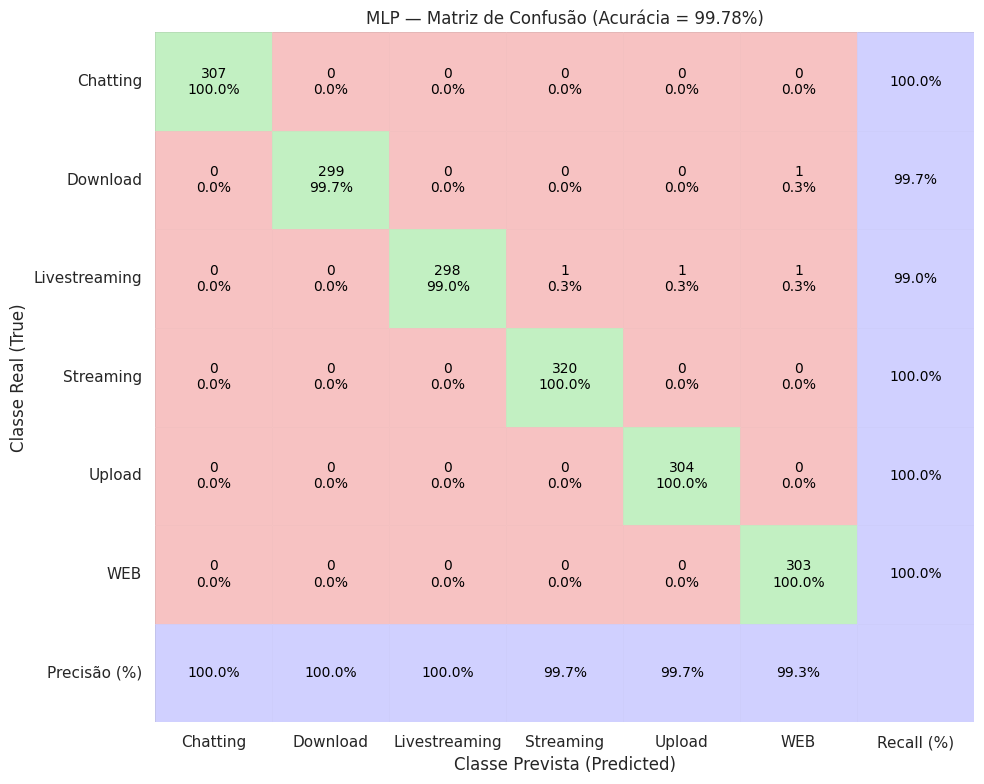

Relatório de Classificação:
                precision    recall  f1-score   support

     Chatting       1.00      1.00      1.00       307
     Download       1.00      1.00      1.00       300
Livestreaming       1.00      0.99      0.99       301
    Streaming       1.00      1.00      1.00       320
       Upload       1.00      1.00      1.00       304
          WEB       0.99      1.00      1.00       303

     accuracy                           1.00      1835
    macro avg       1.00      1.00      1.00      1835
 weighted avg       1.00      1.00      1.00      1835


ℹ️ O modelo MLP não possui cálculo nativo de importância de atributos baseada em árvores.

==================== Resultados Finais ====================
CatBoost        -> Acurácia: 0.9995 | F1-Macro: 0.9994
LightGBM        -> Acurácia: 0.9984 | F1-Macro: 0.9984
RandomForest    -> Acurácia: 0.9995 | F1-Macro: 0.9994
SVM             -> Acurácia: 0.9967 | F1-Macro: 0.9967
MLP             -> Acurácia: 0.9978 | F1-Macro

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.preprocessing import StandardScaler

# === Etapa 1: Nomes das Características ===
feature_names = (
    X_train.columns.tolist() if hasattr(X_train, "columns") else [f"feat_{i}" for i in range(X_train.shape[1])]
)


# === Função auxiliar para converter "clf__param" → "param" ===
def clean_params(params):
    return {k.split("__")[1]: v for k, v in params.items()}


# === Etapa 2: Construir pipelines finais usando os melhores hiperparâmetros ===
final_pipelines = {}

for model_name, config in model_configs.items():
    if model_name not in best_params:
        continue

    final_pipeline = ImbPipeline([
        # ("smote", SMOTE(random_state=42)),
        ("scaler", StandardScaler()),
        ("clf", clone(config["model"]).set_params(**clean_params(best_params[model_name]))),
    ])

    final_pipelines[model_name] = final_pipeline


# === Etapa 3: Treinar, Avaliar e Extrair Feature Importance ===
results = {}
feature_importances_by_model = {}

for name, pipeline in final_pipelines.items():
    print(f"\n{'=' * 20} Treinando modelo final: {name} {'=' * 20}")

    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1_macro = f1_score(y_test, y_pred, average="macro")
    cm = confusion_matrix(y_test, y_pred)
    report = classification_report(y_test, y_pred, target_names=le.classes_)

    print(f"Acurácia: {acc:.4f} | F1-Macro: {f1_macro:.4f}")
    plot_confusion_matrix(y_test, y_pred, class_names=le.classes_, model_name=name)
    print("Relatório de Classificação:\n", report)

    # --- Extração Robusta de Feature Importance ---
    clf = pipeline.named_steps["clf"]
    importances = None

    if hasattr(clf, "feature_importances_"):
        importances = clf.feature_importances_
    elif hasattr(clf, "get_feature_importance"):
        importances = clf.get_feature_importance()

    if importances is not None:
        fi_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)
        feature_importances_by_model[name] = fi_series

        print(f"\n📊 Top 15 Feature Importances ({name}):")
        for rank, (feat, val) in enumerate(fi_series.head(15).items(), 1):
            print(f"  {rank:2d}º | {feat:<30} | {val:.6f}")

        # Se for o Random Forest, gera e salva o gráfico de barras horizontal solicitado
        if name in ["RandomForest", "LightGBM", "CatBoost"]:
            plt.figure(figsize=(9, 5.5))
            top15_plot = fi_series.head(15).sort_values(ascending=True)
            bars = plt.barh(top15_plot.index, top15_plot.values, color="#2b5c8f", edgecolor="black", alpha=0.9)
            plt.xlabel("Importância Média de Redução de Impureza (MDI / Gini)", fontsize=10, fontweight="bold")
            plt.title(f"Top 15 Atributos Mais Relevantes - {name}", fontsize=11, fontweight="bold")
            plt.grid(axis="x", linestyle="--", alpha=0.5)

            for bar in bars:
                w = bar.get_width()
                plt.text(
                    w + (0.01 * w),
                    bar.get_y() + bar.get_height() / 2,
                    f"{w:.4f}",
                    va="center",
                    ha="left",
                    fontsize=8.5,
                )

            plt.xlim(0, max(top15_plot.values) * 1.15)
            plt.tight_layout()
            plt.savefig(f"feature_importance_top15-{name}.png", dpi=300)
            plt.close()
            print("  💾 Gráfico 'feature_importance_top15.png' salvo com sucesso!")
    else:
        print(f"\nℹ️ O modelo {name} não possui cálculo nativo de importância de atributos baseada em árvores.")

    results[name] = {"Acurácia": acc, "F1-Macro": f1_macro}

print(f"\n{'=' * 20} Resultados Finais {'=' * 20}")
for model, metrics in results.items():
    print(f"{model:<15} -> Acurácia: {metrics['Acurácia']:.4f} | F1-Macro: {metrics['F1-Macro']:.4f}")

# **Comparação visual**

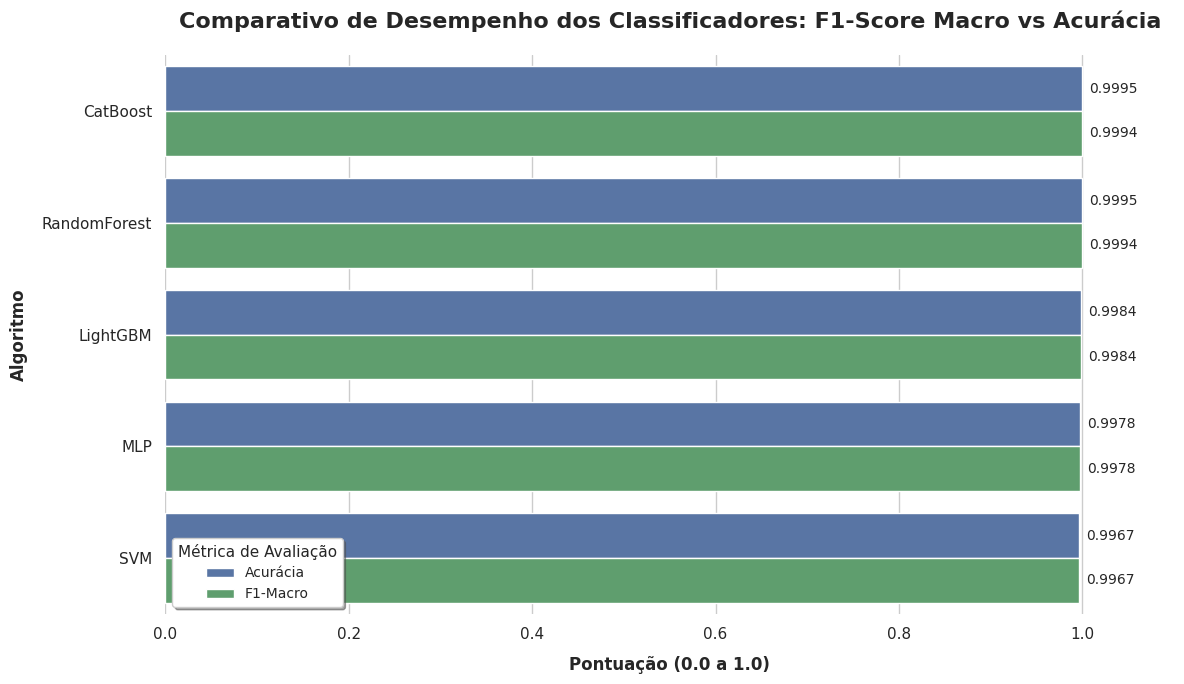

In [ ]:
# 1. Converter o dicionário aninhado para DataFrame
df_resultados = pd.DataFrame.from_dict(results, orient='index').reset_index()
df_resultados.rename(columns={'index': 'Modelo'}, inplace=True)

# 2. Reestruturar (melt) os dados para o formato aceito pelo Seaborn para barras agrupadas
df_melted = df_resultados.melt(
    id_vars='Modelo',
    var_name='Métrica',
    value_name='Pontuação'
)

# 3. Ordenar os modelos com base no melhor F1-Macro (ordem decrescente)
ordem_modelos = df_resultados.sort_values(by='F1-Macro', ascending=False)['Modelo']

# 4. Configuração visual e plotagem (Padrão Acadêmico/Produção)
sns.set_theme(style="whitegrid", rc={"axes.edgecolor": ".8"}) # Grid sutil e limpo
plt.figure(figsize=(12, 7))

# Cores: Azul corporativo e Verde escuro (excelente contraste para artigos impressos ou PDFs)
paleta_cores = ['#4C72B0', '#55A868']

ax = sns.barplot(
    data=df_melted,
    x='Pontuação',
    y='Modelo',
    hue='Métrica',
    order=ordem_modelos,
    palette=paleta_cores
)

# 5. Adicionar os rótulos flutuantes em cada barra (4 casas decimais para rigor técnico)
for container in ax.containers:
    ax.bar_label(container, fmt='%.4f', label_type='edge', padding=5, fontsize=10, fontweight='medium')

# 6. Ajustes finos de tipografia e espaçamento
plt.title("Comparativo de Desempenho dos Classificadores: F1-Score Macro vs Acurácia",
          fontsize=16, fontweight='bold', pad=20)
plt.xlabel("Pontuação (0.0 a 1.0)", fontsize=12, fontweight='bold', labelpad=10)
plt.ylabel("Algoritmo", fontsize=12, fontweight='bold', labelpad=10)

# Expandir o limite do eixo X levemente para caber os rótulos de dados
plt.xlim(0, 1.1)

# Estilização da legenda
plt.legend(title='Métrica de Avaliação', loc='lower left', frameon=True, shadow=True, title_fontsize='11', fontsize='10')

# Limpeza das bordas do gráfico (Tufte style)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

In [ ]:
import time
import pickle
import numpy as np
import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split

# Modelos com os hiperparâmetros ótimos já descobertos
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

# 1. Separação treino/teste (70/30)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.3, stratify=y_encoded, random_state=42
)

# 2. Definição dos modelos ótimos
optimal_models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10, max_features="sqrt", random_state=42
    ),
    "CatBoost": CatBoostClassifier(
        depth=4, iterations=200, l2_leaf_reg=5, learning_rate=0.1,
        verbose=0, random_state=42, task_type="CPU"
    ),
    "LightGBM": LGBMClassifier(
        num_leaves=31, learning_rate=0.1, n_estimators=200, max_depth=5,
        random_state=42, verbose=-1
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(100, 50), activation="relu", alpha=0.0001,
        random_state=42, max_iter=500
    ),
    "SVM": SVC(
        C=10, gamma="scale", probability=True, random_state=42
    )
}

benchmark_results = []
n_runs = 10  # Repetições para amortizar overhead do sistema operacional

print("🚀 Iniciando benchmark computacional dos modelos ótimos...\n")

for name, clf in optimal_models.items():
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("clf", clf)
    ])

    # A) Medição do Tempo de Treinamento
    t_start_train = time.perf_counter()
    pipe.fit(X_train, y_train)
    t_train = time.perf_counter() - t_start_train

    # B) Aquecimento (Warm-up do cache de CPU)
    _ = pipe.predict(X_test.iloc[:50])

    # C) Medição da Latência de Inferência
    t_start_inf = time.perf_counter()
    for _ in range(n_runs):
        y_pred = pipe.predict(X_test)
    t_total_inf = time.perf_counter() - t_start_inf

    # Latência unitária em microsegundos (µs por fluxo/amostra)
    total_inferences = n_runs * len(X_test)
    latency_us = (t_total_inf / total_inferences) * 1_000_000

    # D) Métricas de Acurácia e Tamanho do Objeto
    acc = accuracy_score(y_test, y_pred) * 100
    f1 = f1_score(y_test, y_pred, average="macro")
    model_size_mb = len(pickle.dumps(pipe)) / (1024 * 1024)

    benchmark_results.append({
        "Modelo": name,
        "Tempo de Treino (s)": round(t_train, 2),
        "Latência (µs/fluxo)": round(latency_us, 2),
        "Tamanho (MB)": round(model_size_mb, 2),
        "Acurácia (%)": round(acc, 2),
        "F1-Score Macro": round(f1, 4)
    })

    print(f"✔️ {name:15s} | Treino: {t_train:6.2f}s | Latência: {latency_us:6.2f} µs | F1: {f1:.4f}")

# 3. Exibição e Geração de Código LaTeX
df_benchmark = pd.DataFrame(benchmark_results)
print("\n" + "="*80)
print(df_benchmark.to_string(index=False))
print("="*80)

# Código LaTeX formatado pronto para cópia
print("\n📋 CÓDIGO DA TABELA EM LATEX:\n")
print(df_benchmark.to_latex(index=False, float_format="%.2f"))

🚀 Iniciando benchmark computacional dos modelos ótimos...

✔️ Random Forest   | Treino:   1.44s | Latência:  11.86 µs | F1: 0.9994
✔️ CatBoost        | Treino:   3.40s | Latência:   3.90 µs | F1: 0.9994


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

✔️ LightGBM        | Treino:   1.40s | Latência:  22.76 µs | F1: 0.9984
✔️ MLP             | Treino:   1.57s | Latência:   3.76 µs | F1: 0.9978
✔️ SVM             | Treino:   0.44s | Latência:  32.44 µs | F1: 0.9967

       Modelo  Tempo de Treino (s)  Latência (µs/fluxo)  Tamanho (MB)  Acurácia (%)  F1-Score Macro
Random Forest                 1.44                11.86          0.33         99.95          0.9994
     CatBoost                 3.40                 3.90          0.20         99.95          0.9994
     LightGBM                 1.40                22.76          0.74         99.84          0.9984
          MLP                 1.57                 3.76          0.30         99.78          0.9978
          SVM                 0.44                32.44          0.08         99.67          0.9967

📋 CÓDIGO DA TABELA EM LATEX:

\begin{tabular}{lrrrrr}
\toprule
Modelo & Tempo de Treino (s) & Latência (µs/fluxo) & Tamanho (MB) & Acurácia (%) & F1-Score Macro \\
\midrule
Random Fo